In [ ]:
# Import neccessary libraries
import itertools
import re

import pandas as pd
import numpy as np

# For graph plot
import matplotlib.pyplot as plt
from matplotlib import cm
import seaborn as sns

# For feature scaling and selection
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler, MaxAbsScaler
from sklearn.feature_selection import mutual_info_regression, SequentialFeatureSelector
from sklearn.svm import SVR
from mrmr import mrmr_regression

# For DLNM model
from statsmodels.gam.gam_cross_validation.cross_validators import KFold
import statsmodels.api as sm
from statsmodels.gam.smooth_basis import UnivariateBSplines, UnivariateCubicCyclicSplines
from statsmodels.gam.api import GLMGam, BSplines, CyclicCubicSplines
from statsmodels.gam.gam_cross_validation.gam_cross_validation import MultivariateGAMCVPath
from statsmodels.genmod.families.links import log
from statsmodels.gam.smooth_basis import GenericSmoothers
from pydlnm.basis import CrossBasis
from pydlnm.prediction import crosspred
from pydlnm.utils import logknots
from dlnm import crossbasis, plot_crosspred, cb_pen

from statsmodels.stats.outliers_influence import variance_inflation_factor


In [ ]:
# Function for constructing the CrossBasis matrix
def crossbasis_construct(dataframe, col_lst, max_lag, setting_lst): 
    # setting_lst include the values for the degree and degree of freedom (df) for both exposure and lag dimension in order
    
    # Initlialize the list to place cross basis matrices
    cb_list = []

    # Construct cross basis for each exposure variables
    for col in col_lst:
        tmp_cb = CrossBasis(dataframe[col].values, lag=max_lag, 
                                argvar={"fun": "bs", "degree": setting_lst[0], "df": setting_lst[1]}, 
                                arglag={"fun": "bs", "degree": setting_lst[2], "df": setting_lst[3]})
        cb_list.append(tmp_cb)

    X_exposure = np.concat(cb_list, axis=1)

    # Construct the DataFrame object for later model construction 
    model_data = np.concat([dataframe.to_numpy(), X_exposure], axis=1)
    model_data = pd.DataFrame(model_data)

    # Rename the columns of the mode_data DataFrame 
    exp_name_list = [f"{col}_basis_{i}" for col in col_lst for i in range(tmp_cb.shape[1])]
    model_data.columns = [n for n in dataframe.columns if n!="From"] + exp_name_list

    # Fill in 0 for the missing value(s)
    model_data[exp_name_list] = model_data[exp_name_list].fillna(0)

    # Return the variables that need to be used 
    return model_data, exp_name_list, cb_list

In [4]:
# Function for constructing the smoothers 
def smoothers_construct(dataframe, bs_dict, cs_dict):
    # bs_dict and cs_dict contains the name, degree and df for the spline function constructions needed 
    
    bs_list = []
    # Use B spline for 'time' and 'stringency index'
    for i in range(len(bs_dict["name"])):
        tmp_bs = UnivariateBSplines(dataframe[bs_dict["name"][i]], df=bs_dict["df"][i], degree=bs_dict["degree"][i], include_intercept=False, variable_name=bs_dict["name"][i])
        bs_list.append(tmp_bs)
    
    # Use Cubic Cyclic Spline for 'Week'
    cs = UnivariateCubicCyclicSplines(dataframe[cs_dict["name"]], df=cs_dict["df"], constraints="center", variable_name=cs_dict["name"])

    # Group the two spline functions together to form a single smoother variable
    sm_weights = bs_list + [cs]
    X_smooth = dataframe[bs_dict["name"]+[cs_dict["name"]]]
    smoothers = GenericSmoothers(X_smooth, sm_weights)

    # Return the smoother variable
    return smoothers

In [5]:
# Function for constructing GAM model with Negative Binomial family 
def NB_GAM_model(dataframe, tar_var, exp_names, smoothers, a): 
    # Initializa the formula
    formula = f"{tar_var} ~ {exp_names} + pandemic_flag"

    # Build and fit the model
    NegativeBinomial_gam_model = GLMGam.from_formula(formula, data=dataframe, smoother=smoothers, alpha=a, family=sm.families.NegativeBinomial(alpha=0.5))
    result = NegativeBinomial_gam_model.fit()
    # result = NegativeBinomial_gam_model.fit_regularized(method="l1_slsqp", alpha=1.0)
        # no penalization for Negative Binomial

    # Return the model and the result 
    return NegativeBinomial_gam_model, result

In [51]:
# Function for 
def pred_cal(result, dataframe, cb_lst, mete_lst, i):
    n_cb_cols = cb_lst[i].shape[1]
    start_idx = sum(cb.shape[1] for cb in cb_lst[:i])
    end_idx = start_idx+n_cb_cols
    cb_coef = result.params.values[start_idx:end_idx]
    cb_vcov = result.cov_params().iloc[start_idx:end_idx, start_idx:end_idx]
    at = np.linspace(dataframe[mete_lst[i]].min(), dataframe[mete_lst[i]].max(), 100)
    cen = dataframe[mete_lst[i]].median()
    pred = crosspred(basis=cb_lst[i], coef=cb_coef, vcov=cb_vcov, model_link="log", at=at, cen=cen)
    
    print(f"{mete_lst[i]} RR range: {pred.allRRfit.min():.3f} to {pred.allRRfit.max():.3f}")

    return pred

In [7]:
# Function for plotting the 3D graph 
def graph_3Dplot(pred, exp):
    fig = plot_crosspred(pred, ptype="3d")

    ax = fig.gca()
    ax.set_title("3D Exposure-Lag-Response Association Surface", fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel(exp, fontsize=12, labelpad=10)
    ax.set_ylabel("Lag (Weeks)", fontsize=12, labelpad=10)
    ax.set_zlabel("Residual Risk (RR)", labelpad=10)
    ax.set_yticks(np.linspace(0, 4, pred.matRRfit.shape[1]))

    collections = ax.collections[0]
    vmin, vmax = collections.get_array().min(), collections.get_array().max()

    collections.set_clim(vmin, vmax)
    cbar = fig.colorbar(collections, ax=ax, shrink=0.6, pad=0.1)
    cbar.set_label("Relative Risk (RR)", rotation=270, labelpad=20)

    plt.tight_layout()
    plt.show()

In [ ]:
# Function for plotting the exposure-response slice plot
def graph_expresponseplot(pred, exp):
    fig = plot_crosspred(pred, ptype="overall")
    cen = df[exp].median()

    ax = fig.gca()

    ax.axvline(x=cen, color='black', linestyle=':', linewidth=1.2, label=f'Centering {exp} ({cen:.1f})')
    ax.set_title('Overall Cumulative Exposure-Response Association', fontsize=14, pad=15)
    ax.set_xlabel(exp, fontsize=12)
    ax.legend(loc="best", frameon=True)

    plt.show()

In [9]:
# Function for plotting the lag-response slice plot
def graph_lagresponseplot(pred, target_var):
    fig = plot_crosspred(
        pred, 
        ptype="slices", 
        var=target_var
    )

    ax = fig.gca()

    ax.set_title(f"Lag-Response Curve at {target_var}", fontsize=14, fontweight='bold')
    ax.set_xlabel("Lag (Weeks)", fontsize=12)
    ax.set_ylabel("Relative Risk (RR)", fontsize=12)
    ax.axhline(1, color='gray', linestyle='--', alpha=0.7) # Add baseline at RR=1
    
    plt.show()

In [10]:
# Function for all the three plots at the same time 
def graph_plot(pred, exp, val):
    graph_3Dplot(pred, exp)
    graph_expresponseplot(pred, exp)
    graph_lagresponseplot(pred, val)

In [11]:
def alpha_tune(dataframe, tar_var, exp_names, smoothers, crit, meth):
    model, result = NB_GAM_model(dataframe, tar_var, exp_names, smoothers, [100, 500, 500])
    best_a = model.select_penweight(criterion=crit, method=meth, start_params=np.array([10, 10, 10]))
    return best_a

In [14]:
# Find the degree and degrees of freedom for the CrossBasis
def cb_setting_performance(dataframe, exp_col, setting_options):
    best_setting_idx = 0
    performance = []
    for setting in setting_options:
        model_data, exp_name_list, cb_list = crossbasis_construct(dataframe, exp_col, 4, setting)
        smoothers = smoothers_construct(model_data, {"name": ["time", "ContainmentHealthIndex_Average"], "degree": [3, 3], "df": [6, 4]}, {"name": "Week", "df": 4})
        initial_alpha = [500.0, 500.0, 500.0]
        model, result = NB_GAM_model(model_data, "H1",  " + ".join(exp_name_list), smoothers, initial_alpha)
        print(f"AIC value for the settings {setting}: {result.aic}")
        performance.append([result.aic, result.deviance, result.null_deviance, result.df_resid, result.df_model])

    for i in range(1, len(performance)):
        if performance[i][0] < performance[best_setting_idx][0]:
            best_setting_idx = i

    return setting_options[best_setting_idx]


---

In [65]:
# Import data and basic settings
df = pd.read_csv("data.csv")

df.columns = ["Year", "Week", "From", "temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV", "H1", "H3", "B", "AandB", "ContainmentHealthIndex_Average", "pandemic_flag"]

# Drop unnecessary columns
df.drop(columns=["From"], inplace=True)

# Add a new column <"time"> to df 
df["time"] = np.arange(1, len(df)+1)

mete_col = ["temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV"]
flu_col = ["H1", "H3", "B", "AandB"]
spline_col = ["ContainmentHealthIndex_Average", "Week", "time"]

In [ ]:
# After doing VIF test
mete_col = ["DPT", "WS", "UV"]

df = df[mete_col + flu_col + spline_col + ["pandemic_flag"]]

In [67]:
# overview for df 
display(df.head())
display(df.describe().T)

,DPT,WS,UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,Week,time,pandemic_flag
0,23.20,7.35,4.0,1,12,3.0,19,0.0,36,1,0.0
1,23.80,10.50,3.0,0,6,4.0,15,0.0,37,2,0.0
2,23.20,13.45,4.0,0,4,4.0,13,0.0,38,3,0.0
3,23.25,13.25,3.0,0,2,6.0,10,0.0,39,4,0.0
4,22.40,10.05,3.0,0,6,2.0,8,0.0,40,5,0.0


,count,mean,std,min,25%,50%,75%,max
DPT,1253.0,19.225339,5.963239,-0.10,14.9,20.5,24.8,26.80
WS,1253.0,10.074062,1.811932,5.55,8.8,10.0,11.2,17.80
UV,1253.0,2.891700,1.256406,0.40,2.0,3.0,4.0,7.00
H1,1253.0,69.613727,189.083854,0.00,0.0,4.0,47.0,1999.00
H3,1253.0,115.727055,233.728958,0.00,5.0,28.0,125.0,2560.00
B,1252.0,44.593450,131.615377,0.00,3.0,12.5,41.0,1978.00
AandB,1253.0,261.437350,439.621172,0.00,27.0,103.0,305.0,4679.00
ContainmentHealthIndex_Average,1253.0,8.128132,21.983305,0.00,0.0,0.0,0.0,82.14
Week,1253.0,26.605746,15.077257,1.00,14.0,27.0,40.0,53.00
time,1253.0,627.000000,361.854252,1.00,314.0,627.0,940.0,1253.00


In [68]:
# Grid for the CrossBasis settings 
setting_options = [
    [2, 5, 3, 5], 
    [2, 4, 3, 5], 
    [2, 3, 3, 5], 
    [2, 5, 2, 4],
    [2, 4, 2, 4]
]

# Find the best Cross Basis settings
best_cb_setting = cb_setting_performance(df, mete_col, setting_options)
print(f"The best CrossBasis settings [degree for exposure dimension, df for exposure dimension, degree for lag dimension, df for lag simension]: \n{best_cb_setting}")

AIC value for the settings [2, 5, 3, 5]: 10265.931269191167
AIC value for the settings [2, 4, 3, 5]: 10182.31755950888
AIC value for the settings [2, 3, 3, 5]: 10194.036778622452
AIC value for the settings [2, 5, 2, 4]: 10155.505626749944
AIC value for the settings [2, 4, 2, 4]: 10163.751039351027
The best CrossBasis settings [degree for exposure dimension, df for exposure dimension, degree for lag dimension, df for lag simension]: 
[2, 5, 2, 4]


In [69]:
model_data, exp_name_list, cb_list = crossbasis_construct(df, mete_col, 4, best_cb_setting)

display(model_data.head())
display(model_data.describe())

,DPT,WS,UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,Week,time,...,UV_basis_10,UV_basis_11,UV_basis_12,UV_basis_13,UV_basis_14,UV_basis_15,UV_basis_16,UV_basis_17,UV_basis_18,UV_basis_19
0,23.20,7.35,4.0,1.0,12.0,3.0,19.0,0.0,36.0,1.0,...,0.00,0.000,0.0,0.000,0.000,0.00,0.0,0.0,0.0,0.0
1,23.80,10.50,3.0,0.0,6.0,4.0,15.0,0.0,37.0,2.0,...,0.00,0.000,0.0,0.000,0.000,0.00,0.0,0.0,0.0,0.0
2,23.20,13.45,4.0,0.0,4.0,4.0,13.0,0.0,38.0,3.0,...,0.00,0.000,0.0,0.000,0.000,0.00,0.0,0.0,0.0,0.0
3,23.25,13.25,3.0,0.0,2.0,6.0,10.0,0.0,39.0,4.0,...,0.00,0.000,0.0,0.000,0.000,0.00,0.0,0.0,0.0,0.0
4,22.40,10.05,3.0,0.0,6.0,2.0,8.0,0.0,40.0,5.0,...,0.75,0.875,0.0,0.125,0.125,0.25,0.0,0.0,0.0,0.0


,DPT,WS,UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,Week,time,...,UV_basis_10,UV_basis_11,UV_basis_12,UV_basis_13,UV_basis_14,UV_basis_15,UV_basis_16,UV_basis_17,UV_basis_18,UV_basis_19
count,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1252.000000,1253.000000,1253.000000,1253.000000,1253.000000,...,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000
mean,19.225339,10.074062,2.891700,69.613727,115.727055,44.593450,261.437350,8.128132,26.605746,627.000000,...,0.370399,0.370756,0.130666,0.130790,0.130890,0.130671,0.030261,0.030261,0.030261,0.030172
std,5.963239,1.811932,1.256406,189.083854,233.728958,131.615377,439.621172,21.983305,15.077257,361.854252,...,0.289627,0.327437,0.205850,0.185083,0.185063,0.205498,0.097403,0.085041,0.085041,0.097380
min,-0.100000,5.550000,0.400000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,14.900000,8.800000,2.000000,0.000000,5.000000,3.000000,27.000000,0.000000,14.000000,314.000000,...,0.062500,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,20.500000,10.000000,3.000000,4.000000,28.000000,12.500000,103.000000,0.000000,27.000000,627.000000,...,0.343750,0.416667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,24.800000,11.200000,4.000000,47.000000,125.000000,41.000000,305.000000,0.000000,40.000000,940.000000,...,0.625000,0.625000,0.250000,0.215278,0.215278,0.250000,0.000000,0.000000,0.000000,0.000000
max,26.800000,17.800000,7.000000,1999.000000,2560.000000,1978.000000,4679.000000,82.140000,53.000000,1253.000000,...,0.976562,1.000000,0.694444,0.694444,0.694444,0.694444,1.111111,0.902778,0.791667,1.027778


In [70]:
smoothers = smoothers_construct(model_data, {"name": ["time", "ContainmentHealthIndex_Average"], "degree": [3, 3], "df": [6, 4]}, {"name": "Week", "df": 4})


In [22]:
best_a_bic = alpha_tune(model_data, "H1", " + ".join(exp_name_list), smoothers, "bic", "basinhopping")

print(best_a_bic[1])
print(f"alpha {best_a_bic[0]} is the best tested with BIC")

                    message: ['requested number of basinhopping iterations completed successfully']
                    success: True
                        fun: 10994.80870597238
                          x: [-1.065e+00  4.264e+00  8.779e+00]
                        nit: 10
      minimization_failures: 9
                       nfev: 2207
 lowest_optimization_result:       message: Optimization terminated successfully.
                                   success: True
                                    status: 0
                                       fun: 10994.80870597238
                                         x: [-1.065e+00  4.264e+00
                                              8.779e+00]
                                       nit: 55
                                      nfev: 140
                             final_simplex: (array([[-1.065e+00,
                                                     4.264e+00,
                                                     8.779e+00],
      

In [72]:
best_a_bic = alpha_tune(model_data, "H1", " + ".join(exp_name_list), smoothers, "bic", "nm")

print(best_a_bic[1])
print(f"alpha {best_a_bic[0]} is the best tested with BIC")

(array([2.30258509, 2.30258509, 2.30258509]), np.float64(10507.706919507296), 702, 2000, 1)
alpha [10. 10. 10.] is the best tested with BIC


In [ ]:
best_a_gcv = alpha_tune(model_data, "H1", " + ".join(exp_name_list), smoothers, "gcv", "basinhopping")

print(best_a_gcv[1])
print(f"alpha {best_a_gcv[0]} is the best tested with GCV")

                    message: ['requested number of basinhopping iterations completed successfully']
                    success: True
                        fun: 1.3224999346802209
                          x: [-1.027e+01  5.892e+00 -6.932e+00]
                        nit: 10
      minimization_failures: 0
                       nfev: 1143
 lowest_optimization_result:       message: Optimization terminated successfully.
                                   success: True
                                    status: 0
                                       fun: 1.3224999346802209
                                         x: [-1.027e+01  5.892e+00
                                             -6.932e+00]
                                       nit: 35
                                      nfev: 104
                             final_simplex: (array([[-1.027e+01,
                                                     5.892e+00,
                                                    -6.932e+00],
    

In [73]:
best_a_gcv = alpha_tune(model_data, "H1", " + ".join(exp_name_list), smoothers, "gcv", "nm")

print(best_a_gcv[1])
print(f"alpha {best_a_gcv[0]} is the best tested with GCV")

Optimization terminated successfully.
         Current function value: 1.000000
         Iterations: 39
         Function evaluations: 134
(array([ 12.97122936, -66.23769784,  97.70636078]), np.float64(1.0), 39, 134, 0)
alpha [4.29866235e+05 1.71132830e-29 2.71227258e+42] is the best tested with GCV


In [75]:
model_bic, result_bic = NB_GAM_model(model_data, "H1", " + ".join(exp_name_list), smoothers, best_a_bic[0])
print(result_bic.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:                     H1   No. Observations:                 1253
Model:                         GLMGam   Df Residuals:                  1180.68
Model Family:        NegativeBinomial   Df Model:                        71.32
Link Function:                    Log   Scale:                          1.0000
Method:                         PIRLS   Log-Likelihood:                -4996.3
Date:                Mon, 16 Nov 2026   Deviance:                       3835.7
Time:                        16:30:49   Pearson chi2:                 6.47e+04
No. Iterations:                  1000   Pseudo R-squ. (CS):             0.9978
Covariance Type:            nonrobust                                         
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Interc

In [76]:
for s in smoothers.smoothers:
    if getattr(s, "der_basis", None) is None:
        s.der_basis = np.zeros_like(s.basis)
    if getattr(s, "der2_basis", None) is None:
        s.der2_basis = np.zeros_like(s.basis)

best_a_kfold = model.select_penweight_kfold()
print(f"alpha {best_a_kfold[0]} is the best tested with kfold")

alpha (np.float64(10000000.0), np.float64(125.89254117941663), np.float64(1.0)) is the best tested with kfold


In [77]:
# Model diagnotics / Goodness-of-fit
print(f"AIC: {result_bic.aic}")
print(f"BIC: {result_bic.bic}")
print(f"Deviance: {result_bic.deviance}")
print(f"Pearson Chi2: {result_bic.pearson_chi2}")
print(f"Scale/Dispersion: {result_bic.scale}")
print(f"Effective degree of freedom: \n{result_bic.edf}")
print(f"Total EDF: {result_bic.edf.sum()}")

AIC: 10137.297774652474
BIC: 10508.527740520734
Deviance: 3835.706756173445
Pearson Chi2: 64722.24407104822
Scale/Dispersion: 1.0
Effective degree of freedom: 
[-0.42558927  1.01940351  1.15969581  1.02945603  1.0217475   0.91220585
  1.15221831  0.90281103  1.00011502  0.89123615  0.91211219  0.92181636
  0.8252377   1.03260253  0.86862107  0.77024415  0.68866925  1.17463036
  0.95219448  1.04749941  0.86575085  0.96453788  1.20373626  1.23845892
  1.12699141  1.01988496  1.14130143  0.93225637  0.9391229   1.14290059
  0.88326901  1.18529463  1.03822424  1.02452216  0.90684225  1.08375282
  1.08364589  1.05852122  0.99097454  0.70364241  0.64733764  0.95790191
  0.99359161  0.88012769  0.97605924  1.01219691  1.15195164  1.058225
  1.16616641  0.93095153  0.82774612  0.89450895  1.01239468  1.05627743
  0.93211048  0.92330708  0.86996789  0.86272173  1.09340092  0.90945014
  1.07894449  0.83975247  0.58708794  1.5464826   1.34256484  1.14325741
  1.40276271  1.67664661  0.6492087   0

In [78]:
X = np.asarray(model_bic.exog)

print("Design matrix shape:", X.shape)
print("Condition number:", np.linalg.cond(X))
print("Matrix rank:", np.linalg.matrix_rank(X))

Design matrix shape: (1253, 73)
Condition number: 169.49710652977365
Matrix rank: 73


In [ ]:
X = pd.DataFrame(model_bic.exog)

vif = pd.DataFrame({
    "Variable": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})


display(vif.sort_values("VIF", ascending=False))

,Variable,VIF
15,15,91.213035
14,14,91.040712
6,6,47.828193
7,7,47.430074
2,2,45.192728
3,3,44.926945
11,11,43.264202
10,10,43.164309
50,50,41.242140
51,51,41.192536


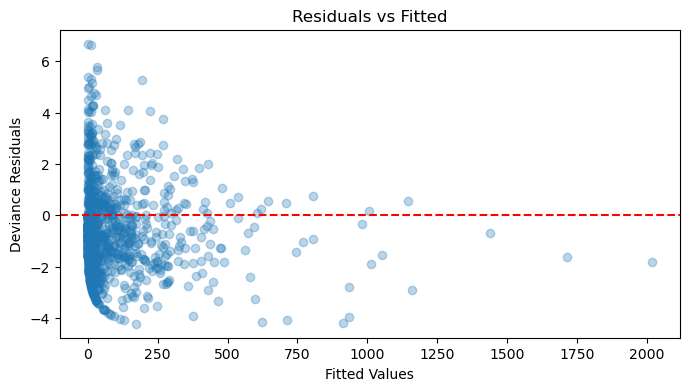

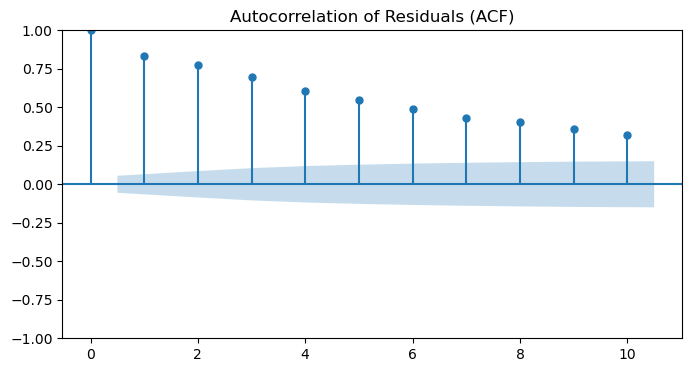

In [80]:
# Residual diagnotics

# Extract deviance residuals
residuals = result_bic.resid_deviance

# 1. Residuals vs. Fitted Values Plot (checks for systematic bias)
plt.figure(figsize=(8, 4))
plt.scatter(result_bic.fittedvalues, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Fitted Values")
plt.ylabel("Deviance Residuals")
plt.title("Residuals vs Fitted")
plt.show()

# 2. Autocorrelation Check (ACF) - Vital for time series!
# Time-series data often has uncaptured temporal patterns; residuals should look like white noise.
fig, ax = plt.subplots(figsize=(8, 4))
sm.graphics.tsa.plot_acf(residuals, lags=10, ax=ax)
plt.title("Autocorrelation of Residuals (ACF)")
plt.show()

In [81]:
model_gcv, result_gcv = NB_GAM_model(model_data, "H1", " + ".join(exp_name_list), smoothers, best_a_gcv[0])


In [82]:
# Model diagnotics / Goodness-of-fit
print(f"AIC: {result_gcv.aic}")
print(f"BIC: {result_gcv.bic}")
print(f"Deviance: {result_gcv.deviance}")
print(f"Pearson Chi2: {result_gcv.pearson_chi2}")
print(f"Scale/Dispersion: {result_gcv.scale}")
print(f"Effective degree of freedom: \n{result_gcv.edf}")
print(f"Total EDF: {result_gcv.edf.sum()}")

AIC: 188469.91446416668
BIC: 188469.91446416668
Deviance: 182312.95955049442
Pearson Chi2: 33774208.66666667
Scale/Dispersion: 1.0
Effective degree of freedom: 
[2.31733611e-21 2.75919085e-22 2.83026499e-22 2.88399060e-22
 3.09443986e-22 7.17591247e-22 6.86162988e-22 6.92893507e-22
 7.49111500e-22 3.38040370e-22 3.01259717e-22 2.90745210e-22
 2.83897433e-22 3.75318417e-22 3.68248972e-22 3.72565606e-22
 3.74516113e-22 1.34520275e-22 1.07968829e-22 8.91433436e-23
 7.60399448e-23 1.62307243e-22 1.34121484e-22 1.32834868e-22
 1.62817897e-22 8.51661766e-22 7.74920316e-22 7.86708063e-22
 8.81307741e-22 7.22396847e-22 6.12713164e-22 5.97739231e-22
 6.64423089e-22 7.52882941e-23 5.66027263e-23 5.73399067e-23
 7.72324049e-23 5.26219633e-24 2.61877427e-24 2.19724951e-24
 3.42392483e-24 3.33733776e-22 3.24588991e-22 3.31036184e-22
 3.66967580e-22 7.02204714e-22 6.39937843e-22 6.44719525e-22
 7.09036737e-22 4.11441505e-22 3.36009460e-22 3.29193857e-22
 3.83728649e-22 8.50651944e-23 6.76518181e-23 

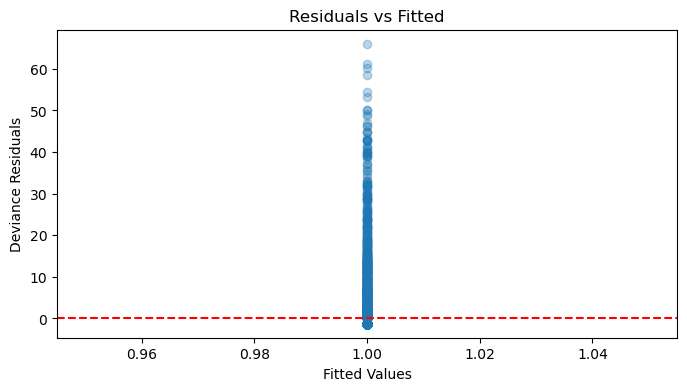

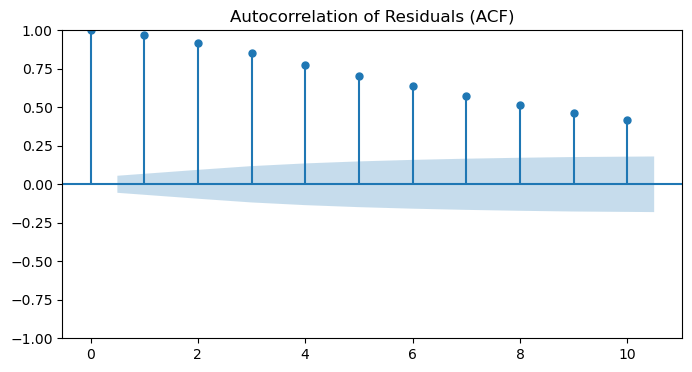

In [83]:
# Residual diagnotics

# Extract deviance residuals
residuals = result_gcv.resid_deviance

# 1. Residuals vs. Fitted Values Plot (checks for systematic bias)
plt.figure(figsize=(8, 4))
plt.scatter(result_gcv.fittedvalues, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Fitted Values")
plt.ylabel("Deviance Residuals")
plt.title("Residuals vs Fitted")
plt.show()

# 2. Autocorrelation Check (ACF) - Vital for time series!
# Time-series data often has uncaptured temporal patterns; residuals should look like white noise.
fig, ax = plt.subplots(figsize=(8, 4))
sm.graphics.tsa.plot_acf(residuals, lags=10, ax=ax)
plt.title("Autocorrelation of Residuals (ACF)")
plt.show()

In [84]:
model_kfold, result_kfold = NB_GAM_model(model_data, "H1", " + ".join(exp_name_list), smoothers, best_a_kfold[0])


In [86]:
# Model diagnotics / Goodness-of-fit
print(f"AIC: {result_kfold.aic}")
print(f"BIC: {result_kfold.bic}")
print(f"Deviance: {result_kfold.deviance}")
print(f"Pearson Chi2: {result_kfold.pearson_chi2}")
print(f"Scale/Dispersion: {result_kfold.scale}")
print(f"Effective degree of freedom: \n{result_kfold.edf}")
print(f"Total EDF: {result_kfold.edf.sum()}")

AIC: 10754.477211843689
BIC: 11125.847615947023
Deviance: 4452.831476770751
Pearson Chi2: 7655.876582680588
Scale/Dispersion: 1.0
Effective degree of freedom: 
[0.89720315 1.07351996 1.05564218 0.99897537 1.28049093 0.885461
 0.89426996 0.95866476 1.08832974 0.91848973 0.84779769 0.85351494
 0.83499998 1.01036839 0.9190534  0.75203455 0.73780869 1.64883502
 1.37428504 1.10093329 0.86578869 0.80934926 1.19890885 0.6302208
 0.89157458 1.09137017 1.27929912 0.47124927 0.7481676  0.9164245
 0.65746844 0.99424891 0.97812031 1.04244235 1.03227321 1.16225906
 1.17214731 0.93402542 0.82635524 0.78062562 0.81993891 1.17219916
 1.16672248 0.665839   1.18243356 1.0477438  1.10236442 0.90869012
 1.11112293 0.65367571 0.99464154 0.77051243 1.2589501  1.27699628
 1.06277705 1.09909516 0.99429745 0.97978838 0.50852023 1.04362847
 0.54016081 0.76027884 1.29195477 1.19632918 1.23654519 0.71174949
 1.36688905 1.22095186 0.72172115 0.99923583 0.87198836 1.46802888
 1.52664365]
Total EDF: 72.3454107003368

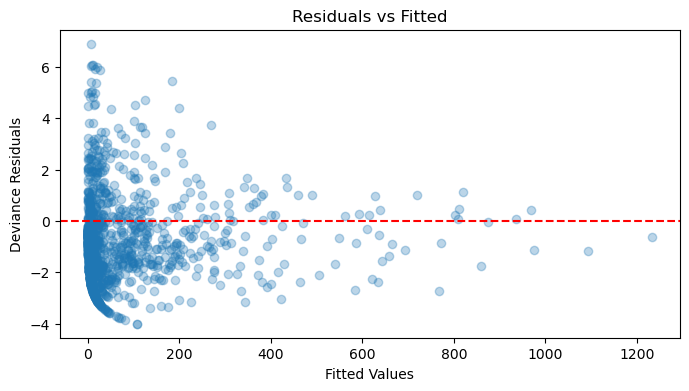

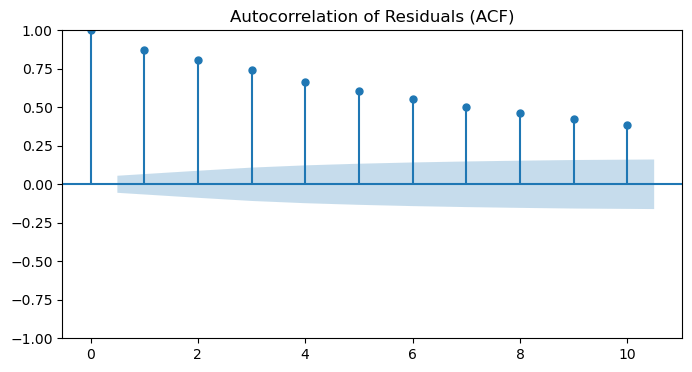

In [87]:
# Residual diagnotics

# Extract deviance residuals
residuals = result_kfold.resid_deviance

# 1. Residuals vs. Fitted Values Plot (checks for systematic bias)
plt.figure(figsize=(8, 4))
plt.scatter(result_kfold.fittedvalues, residuals, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Fitted Values")
plt.ylabel("Deviance Residuals")
plt.title("Residuals vs Fitted")
plt.show()

# 2. Autocorrelation Check (ACF) - Vital for time series!
# Time-series data often has uncaptured temporal patterns; residuals should look like white noise.
fig, ax = plt.subplots(figsize=(8, 4))
sm.graphics.tsa.plot_acf(residuals, lags=10, ax=ax)
plt.title("Autocorrelation of Residuals (ACF)")
plt.show()

In [88]:
# Comparison for using BIC / GCV / Kfold for choosing alpha 
results = {}

results["BIC"] = {"alpha": best_a_bic[0], "AIC": result_bic.aic, "BIC": result_bic.bic, "GCV": result_bic.gcv, "EDF": result_bic.edf.sum()}
results["GCV"] = {"alpha": best_a_gcv[0], "AIC": result_gcv.aic, "BIC": result_gcv.bic, "GCV": result_gcv.gcv, "EDF": result_gcv.edf.sum()}
results["KFold"] = {"alpha": best_a_kfold[0], "AIC": result_kfold.aic, "BIC": result_kfold.bic, "GCV": result_kfold.gcv, "EDF": result_kfold.edf.sum()}

print("Alpha values comparison using BIC/GCV/Kfold: ")
display(pd.DataFrame(results).T)

Alpha values comparison using BIC/GCV/Kfold: 


,alpha,AIC,BIC,GCV,EDF
BIC,"[10.000000000000002, 10.000000000000002, 10.00...",10137.297775,10508.527741,1.126254,72.318052
GCV,"[429866.234707949, 1.7113283041628024e-29, 2.7...",188469.914464,188469.914464,1.0,0.0
KFold,"(10000000.0, 125.89254117941663, 1.0)",10754.477212,11125.847616,1.126306,72.345411


DPT RR range: 0.484 to 725.645


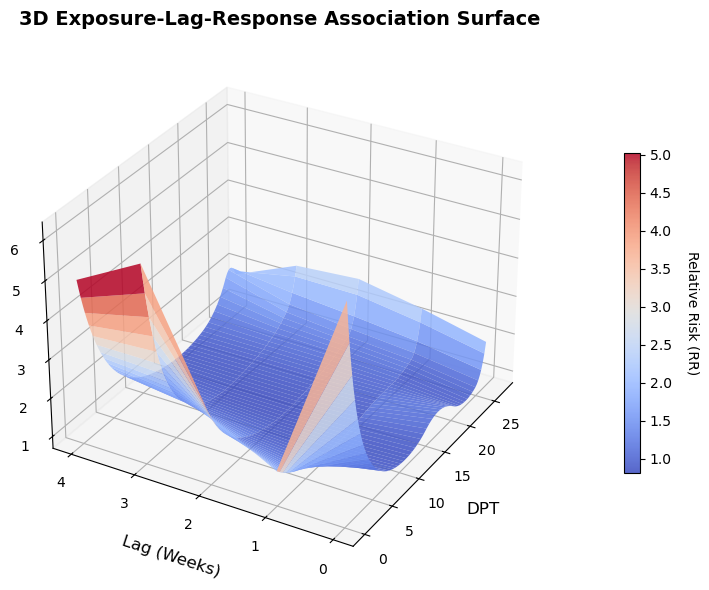

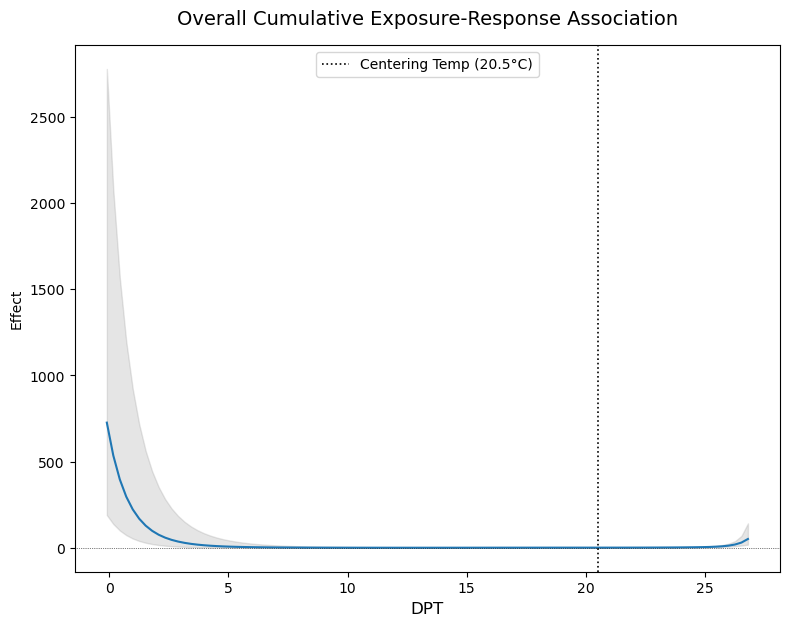

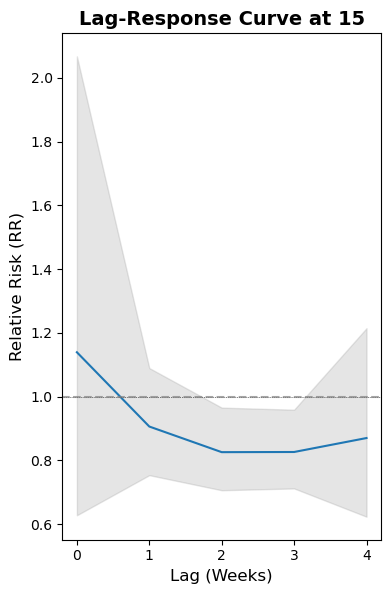

WS RR range: 0.321 to 3.388


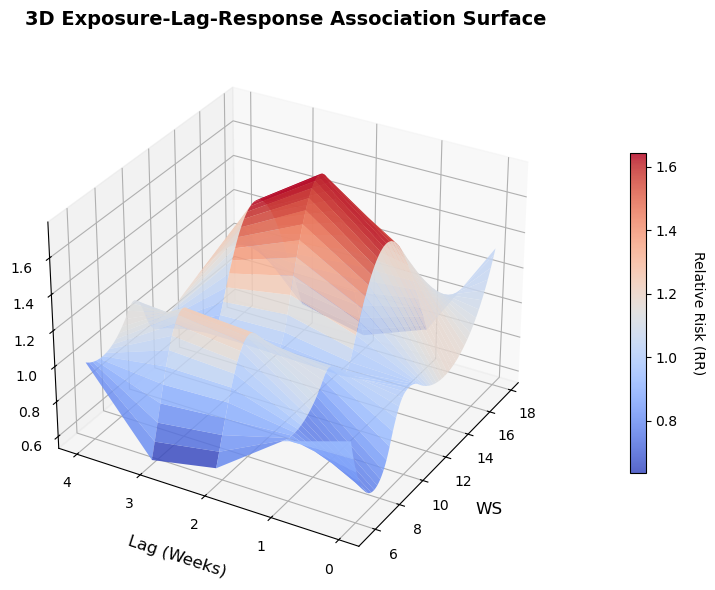

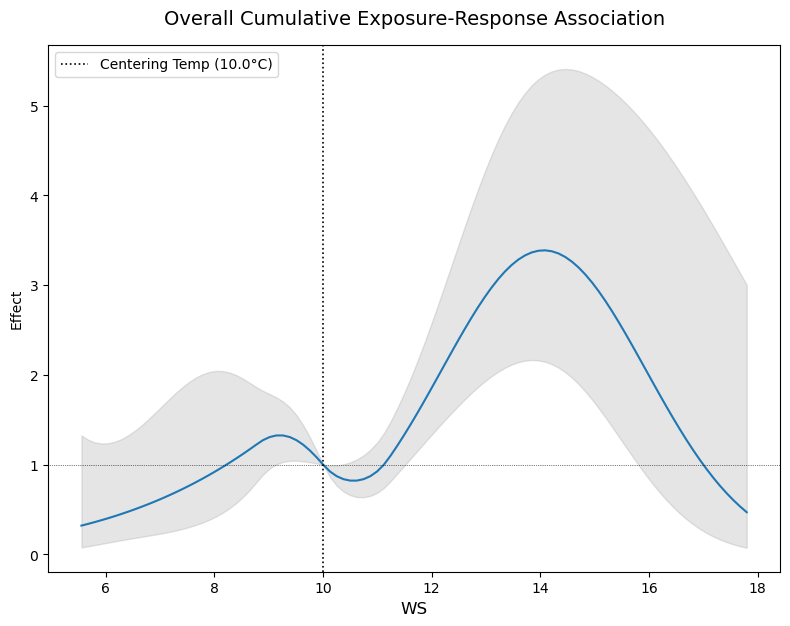

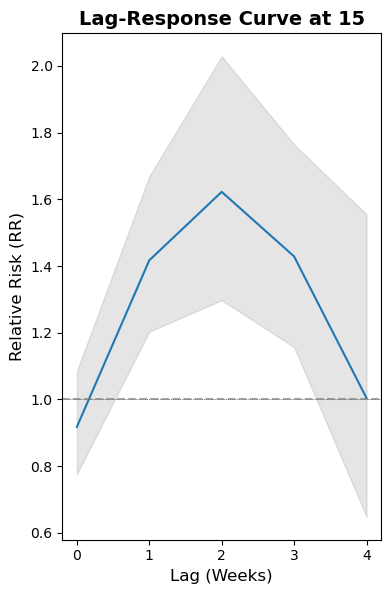

UV RR range: 0.295 to 166.033


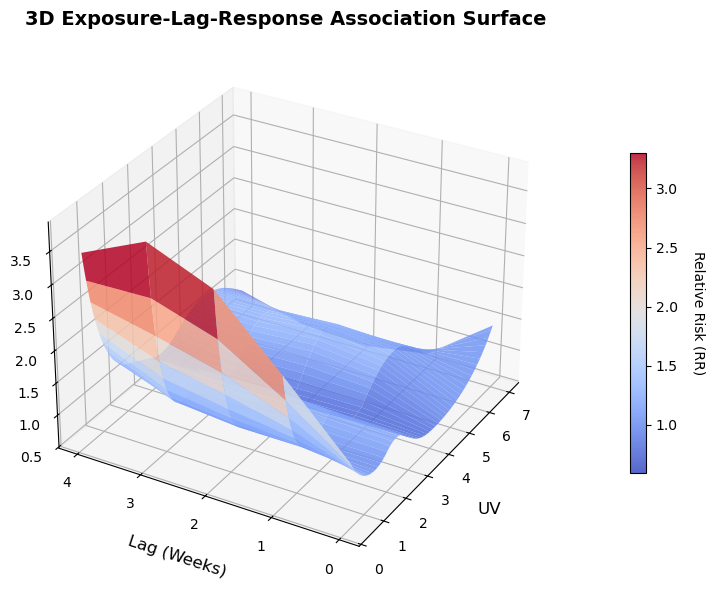

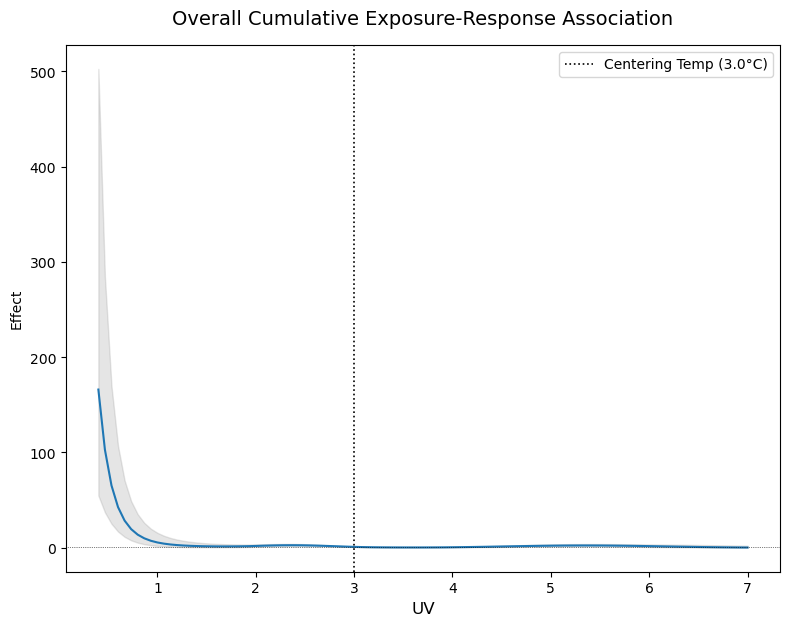

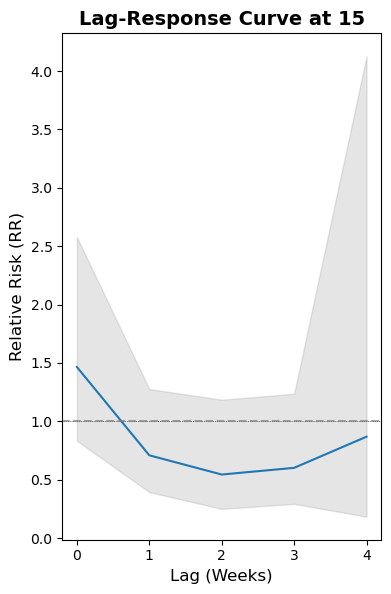

In [89]:
# Graph plots
for i in range(len(mete_col)):
    pred = pred_cal(result_bic, model_data, cb_list, mete_col, i)
    graph_plot(pred, mete_col[i], 15)

DPT RR range: 1.000 to 1.000


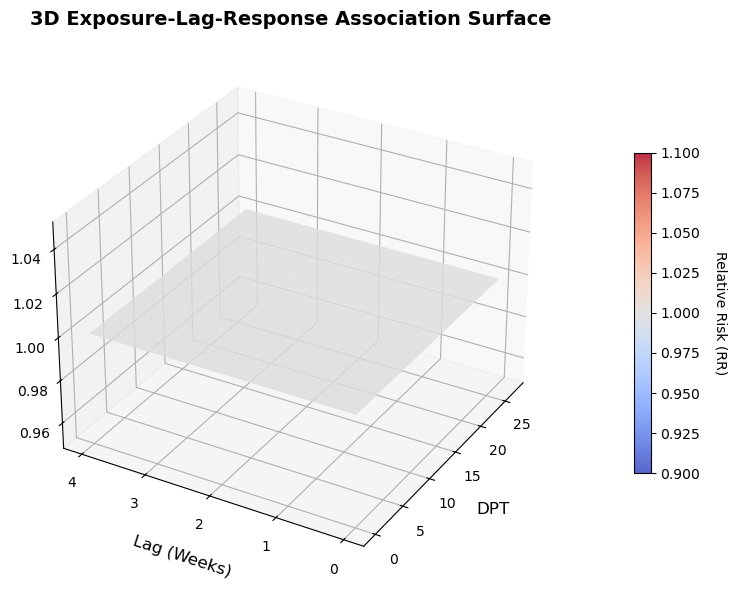

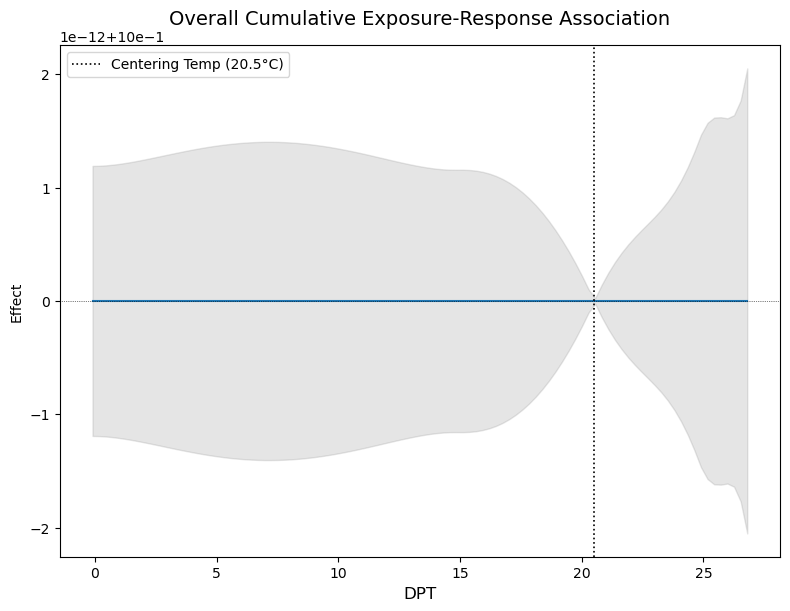

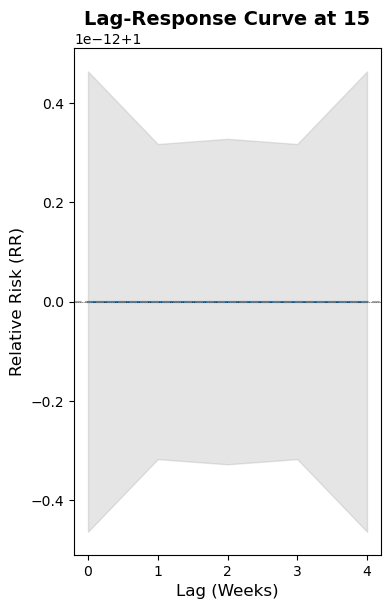

WS RR range: 1.000 to 1.000


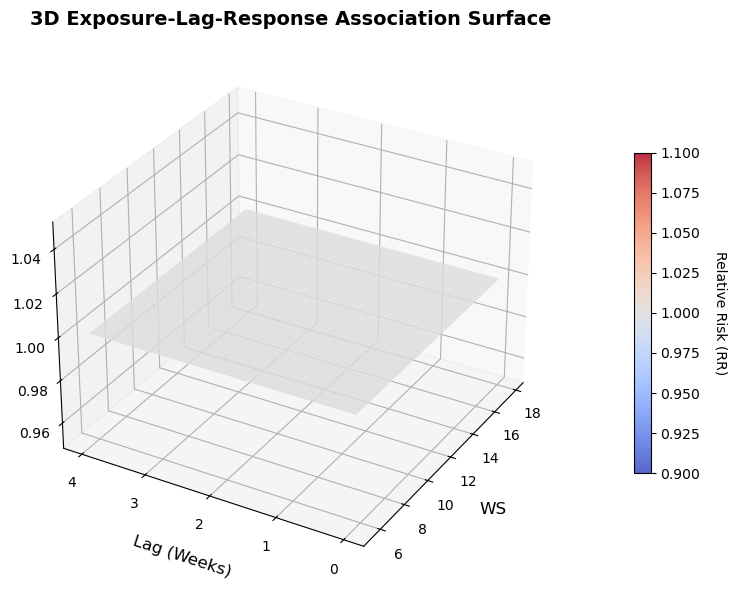

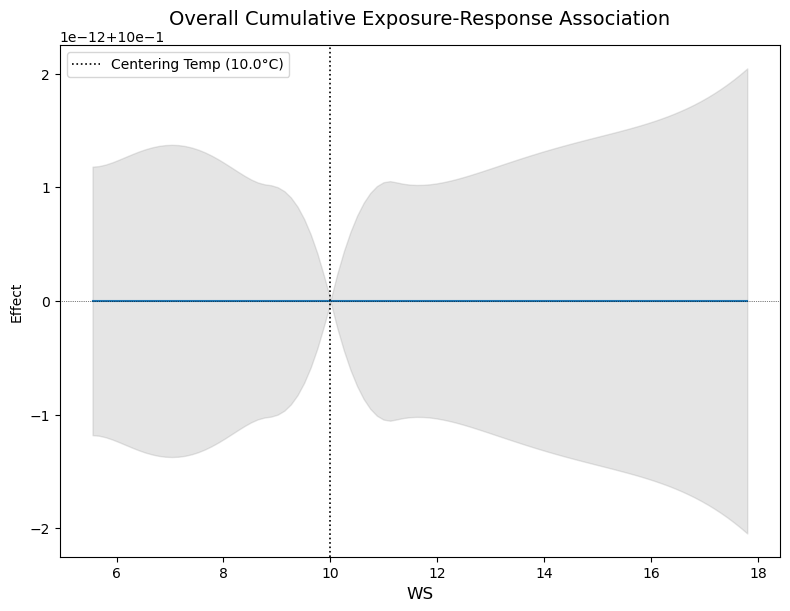

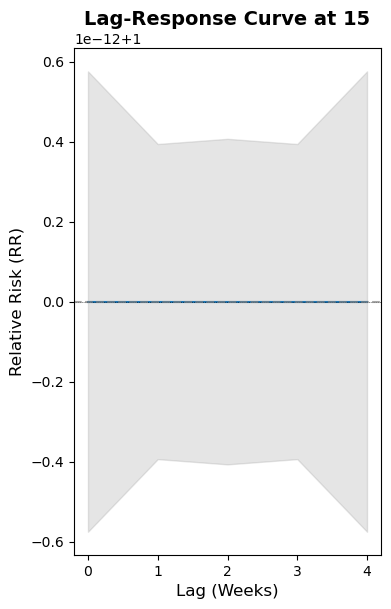

UV RR range: 1.000 to 1.000


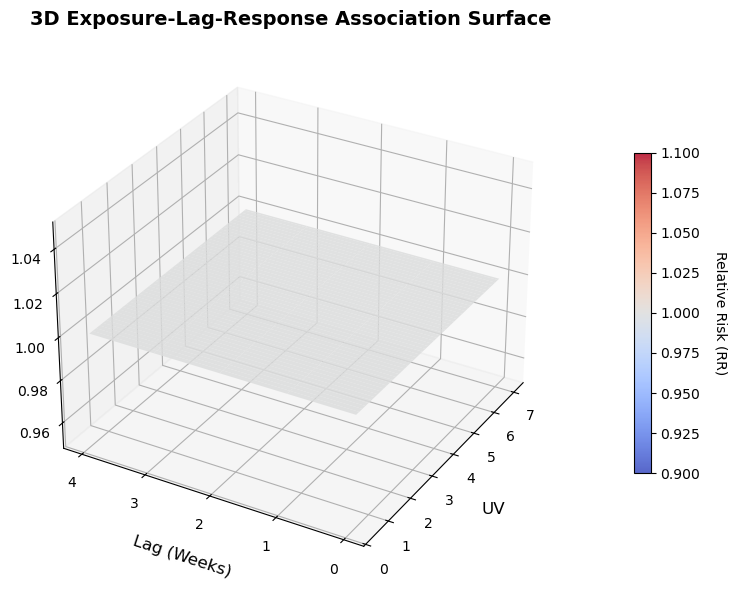

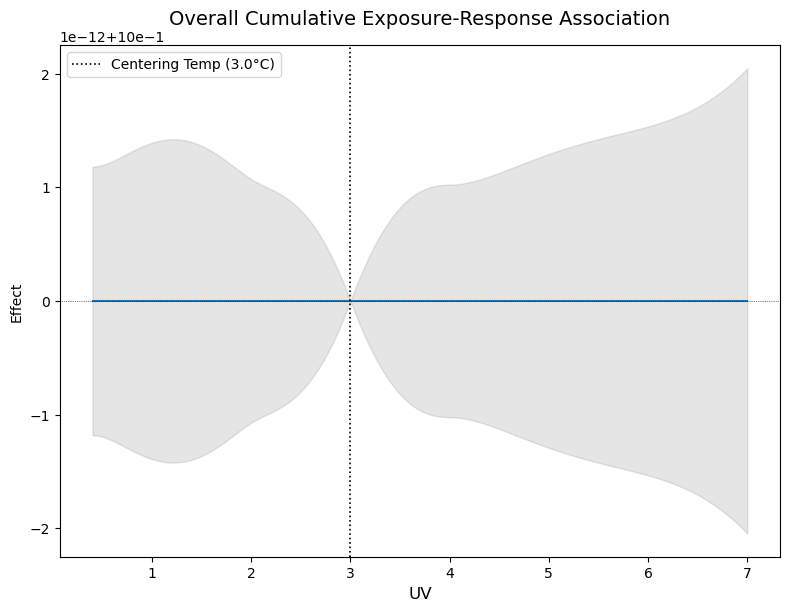

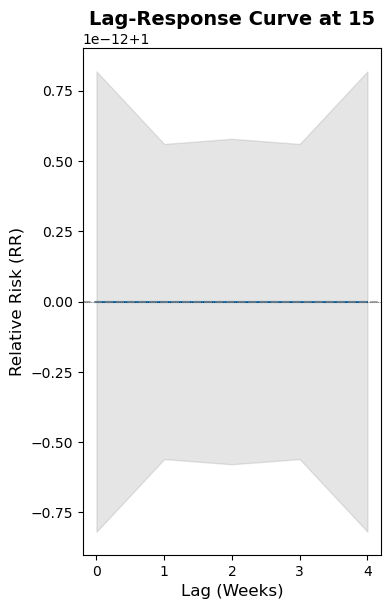

In [92]:
# Graph plots
for i in range(len(mete_col)):
    pred = pred_cal(result_gcv, model_data, cb_list, mete_col, i)
    graph_plot(pred, mete_col[i], 15)

DPT RR range: 0.830 to 79.562


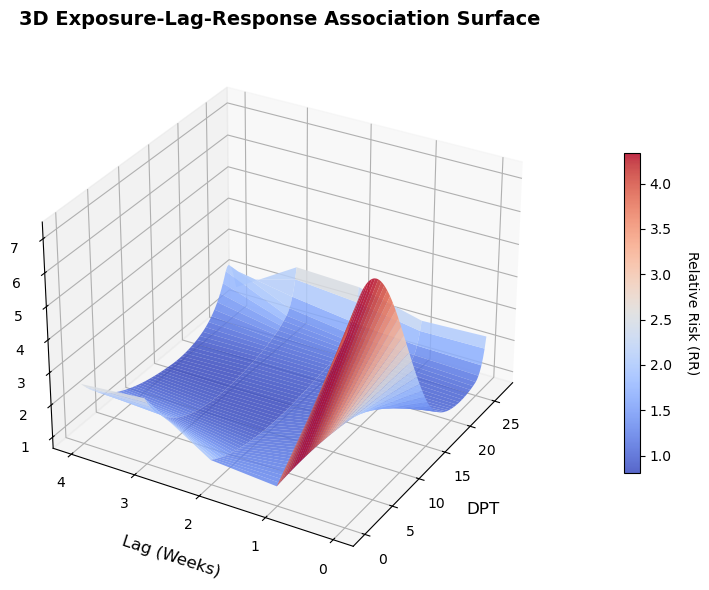

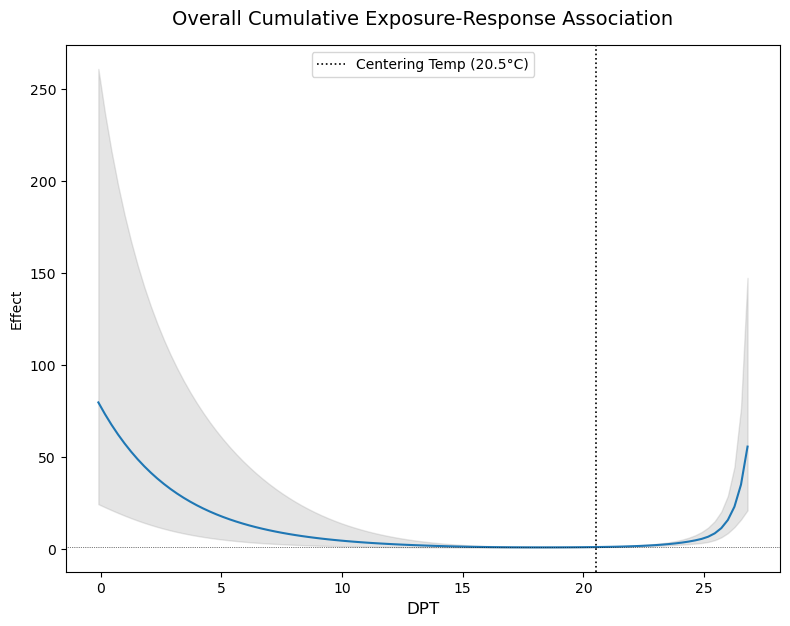

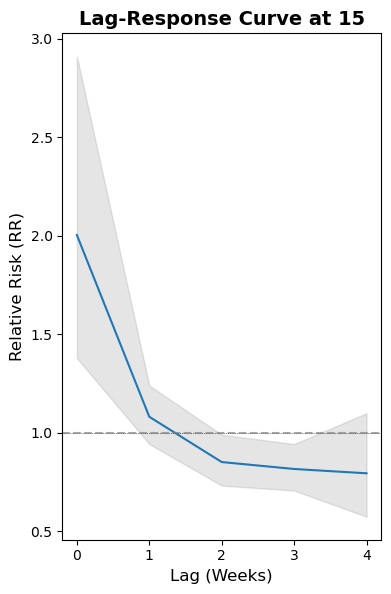

WS RR range: 0.025 to 5.252


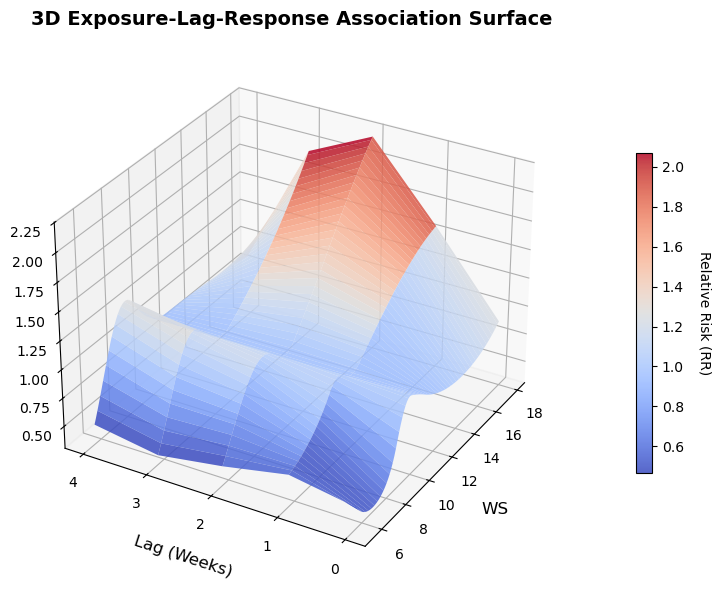

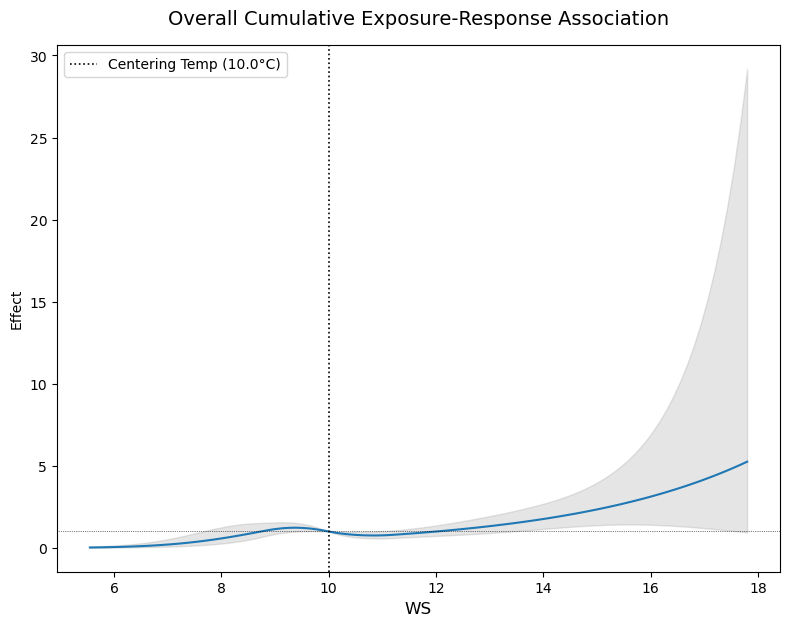

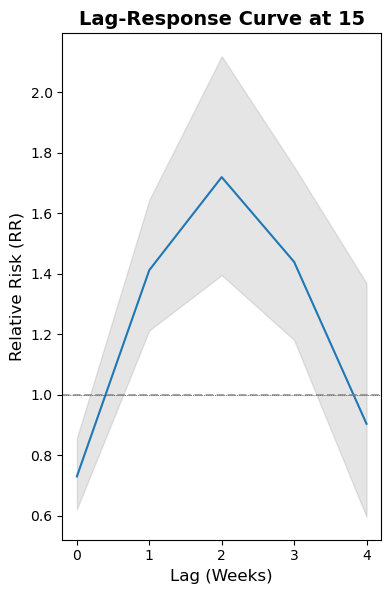

UV RR range: 0.484 to 31.426


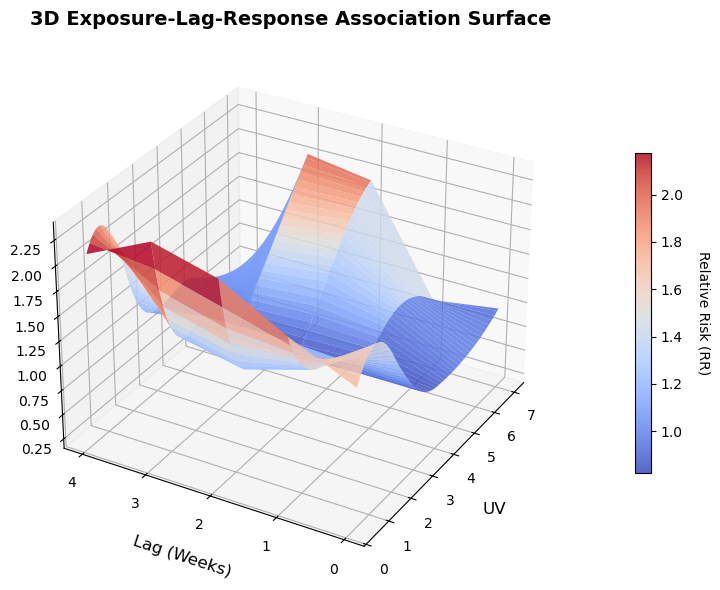

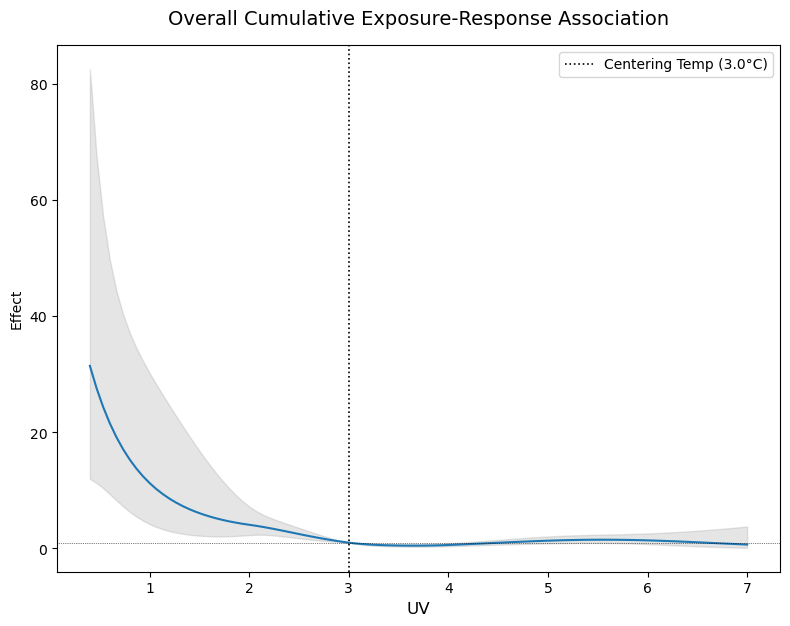

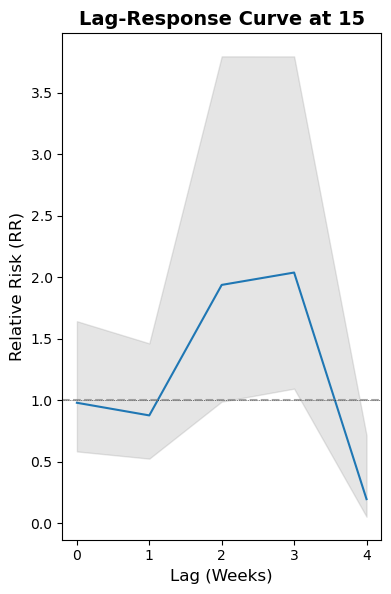

In [91]:
# Graph plots
for i in range(len(mete_col)):
    pred = pred_cal(result_kfold, model_data, cb_list, mete_col, i)
    graph_plot(pred, mete_col[i], 15)

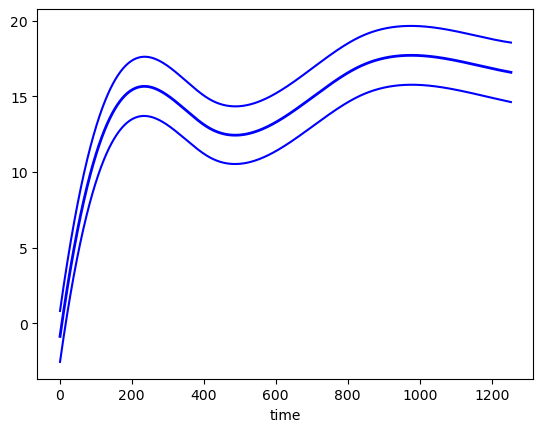

In [93]:
result.plot_partial(0)
plt.show()